# 01 — Exploration des données

Station : **La Durance à Embrun [La Clapière]** (X031001001), 44,555°N 6,498°E, 786 m.
Période : **2023**.

In [1]:
%matplotlib inline
import time
from datetime import datetime

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## 1. Station

Source : API Hub'Eau (référentiel des stations).

In [2]:
STATION_CODE = "X031001001"
STATION_NOM = "La Durance à Embrun [La Clapière]"
LAT, LON = 44.555356405, 6.498009964
ALTITUDE_STATION_M = 786.0   # altitude_ref_alti_station (Hub'Eau)

print(f"{STATION_NOM} ({STATION_CODE})\n{LAT}°N, {LON}°E, {ALTITUDE_STATION_M} m")

La Durance à Embrun [La Clapière] (X031001001)
44.555356405°N, 6.498009964°E, 786.0 m


## 2. Téléchargement Open-Meteo (2023)

Archive API, variables horaires + journalières en un appel. Retry sur 429/5xx (cf. `river.py::fetch_weather_data_multi`).

In [3]:
ANNEE = 2023
DEBUT, FIN = f"{ANNEE}-01-01", f"{ANNEE}-12-31"

# Horaire : les variables qui varient vite (pluie, neige, sol de surface, rayonnement...)
HOURLY_VARS = ["precipitation", "temperature_2m", "snow_depth", "shortwave_radiation",
               "rain", "soil_moisture_7_to_28cm", "snowfall", "soil_moisture_28_to_100cm"]
# Journalier : les agrégats dont l'intérêt est justement de résumer la journée
DAILY_VARS = ["temperature_2m_max", "et0_fao_evapotranspiration"]


def telecharger_meteo(lat, lon, start_date, end_date, hourly_vars, daily_vars, max_retries=5):
    """Un appel Open-Meteo, retry avec backoff sur 429 / 5xx (cf. river.py fetch_weather_data_multi)."""
    url = ("https://archive-api.open-meteo.com/v1/archive"
           if datetime.strptime(end_date, "%Y-%m-%d") < datetime.now()
           else "https://api.open-meteo.com/v1/forecast")
    params = {"latitude": lat, "longitude": lon, "start_date": start_date, "end_date": end_date,
              "hourly": hourly_vars, "daily": daily_vars, "timezone": "Europe/Paris"}
    for tentative in range(max_retries):
        r = requests.get(url, params=params, timeout=180)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:
            attente = 60 if tentative == 0 else min(60, 20 * tentative)
            print(f"429 (quota minute) : nouvel essai dans {attente}s...")
            time.sleep(attente)
        elif r.status_code in (500, 502, 503, 504):
            attente = min(30, 4 * (tentative + 1))
            print(f"{r.status_code} (erreur serveur transitoire) : nouvel essai dans {attente}s...")
            time.sleep(attente)
        else:
            raise Exception(f"Erreur Open-Meteo {r.status_code} : {r.text[:200]}")
    raise Exception("Échec après plusieurs tentatives")


t0 = time.time()
data = telecharger_meteo(LAT, LON, DEBUT, FIN, HOURLY_VARS, DAILY_VARS)
print(f"Téléchargé en {time.time() - t0:.1f}s | altitude utilisée par Open-Meteo : {data['elevation']} m "
      f"(altitude officielle de la station : {ALTITUDE_STATION_M} m)")

Téléchargé en 1.1s | altitude utilisée par Open-Meteo : 788.0 m (altitude officielle de la station : 786.0 m)


In [4]:
df_h = pd.DataFrame(data["hourly"]); df_h["date"] = pd.to_datetime(df_h["time"]); df_h = df_h.drop(columns="time")
df_j = pd.DataFrame(data["daily"]); df_j["date"] = pd.to_datetime(df_j["time"]); df_j = df_j.drop(columns="time")

print("horaire   :", df_h.shape, "lignes/colonnes")
print("journalier:", df_j.shape, "lignes/colonnes")
print("\nvaleurs manquantes (horaire)  :", df_h.isna().sum().to_dict())
print("valeurs manquantes (journalier):", df_j.isna().sum().to_dict())

horaire   : (8760, 9) lignes/colonnes
journalier: (365, 3) lignes/colonnes

valeurs manquantes (horaire)  : {'precipitation': 0, 'temperature_2m': 0, 'snow_depth': 0, 'shortwave_radiation': 0, 'rain': 0, 'soil_moisture_7_to_28cm': 0, 'snowfall': 0, 'soil_moisture_28_to_100cm': 0, 'date': 0}
valeurs manquantes (journalier): {'temperature_2m_max': 0, 'et0_fao_evapotranspiration': 0, 'date': 0}


## 3. Débit (Hub'Eau)

`QmnJ`, même station/année. L/s → m³/s.

In [5]:
def telecharger_debit(station_code, start_date, end_date, max_retries=4):
    """Débit moyen journalier QmnJ (cf. river.py fetch_river_data)."""
    url = "https://hubeau.eaufrance.fr/api/v2/hydrometrie/obs_elab"
    params = {
        "code_entite": station_code,
        "grandeur_hydro_elab": "QmnJ",
        "date_debut_obs_elab": pd.to_datetime(start_date).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "date_fin_obs_elab": pd.to_datetime(end_date).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "size": 20000, "sort": "asc",
    }
    for tentative in range(max_retries):
        r = requests.get(url, params=params, timeout=60)
        if r.status_code in (200, 206):
            data = r.json().get("data", [])
            if not data:
                raise Exception(f"Aucune donnée QmnJ pour {station_code} entre {start_date} et {end_date}.")
            df = pd.DataFrame(data)[["date_obs_elab", "resultat_obs_elab"]]
            df = df.rename(columns={"date_obs_elab": "date", "resultat_obs_elab": "debit_L_s"})
            df["date"] = pd.to_datetime(df["date"])
            df["debit_m3_s"] = df["debit_L_s"] / 1000
            return df
        elif r.status_code in (429, 500, 502, 503, 504):
            attente = min(30, 3 * (tentative + 1))
            print(f"Hub'Eau {r.status_code} (transitoire) : nouvel essai dans {attente}s...")
            time.sleep(attente)
        else:
            raise Exception(f"Erreur Hub'Eau {r.status_code} : {r.text[:200]}")
    raise Exception("Hub'Eau injoignable après plusieurs tentatives")


df_q = telecharger_debit(STATION_CODE, DEBUT, FIN)
print("débit :", df_q.shape, "lignes/colonnes | valeurs manquantes :", df_q["debit_m3_s"].isna().sum())
print(f"min {df_q.debit_m3_s.min():.1f} m³/s, moyen {df_q.debit_m3_s.mean():.1f} m³/s, "
      f"max {df_q.debit_m3_s.max():.1f} m³/s")

débit : (365, 3) lignes/colonnes | valeurs manquantes : 0
min 15.7 m³/s, moyen 53.1 m³/s, max 313.2 m³/s


## 4. Encodage cyclique de la date

`sin`/`cos(2π · jour_de_l'année / 365,25)` — cf. `river.py::encode_cyclical_date`.

In [6]:
# Reprend exactement river.py::GestionnaireDonnees.encode_cyclical_date
# (365,25 jours pour rester correct les années bissextiles)
df_j["sin_date"] = np.sin(2 * np.pi * df_j["date"].dt.dayofyear / 365.25)
df_j["cos_date"] = np.cos(2 * np.pi * df_j["date"].dt.dayofyear / 365.25)
df_j[["date", "sin_date", "cos_date"]].iloc[[0, 90, 181, 273, 364]]

,date,sin_date,cos_date
0,2023-01-01,0.017202,0.999852
90,2023-04-01,0.999986,0.005376
181,2023-07-01,0.010751,-0.999942
273,2023-10-01,-0.999999,0.001075
364,2023-12-31,-0.004301,0.999991


## 5. Débit et variables météo

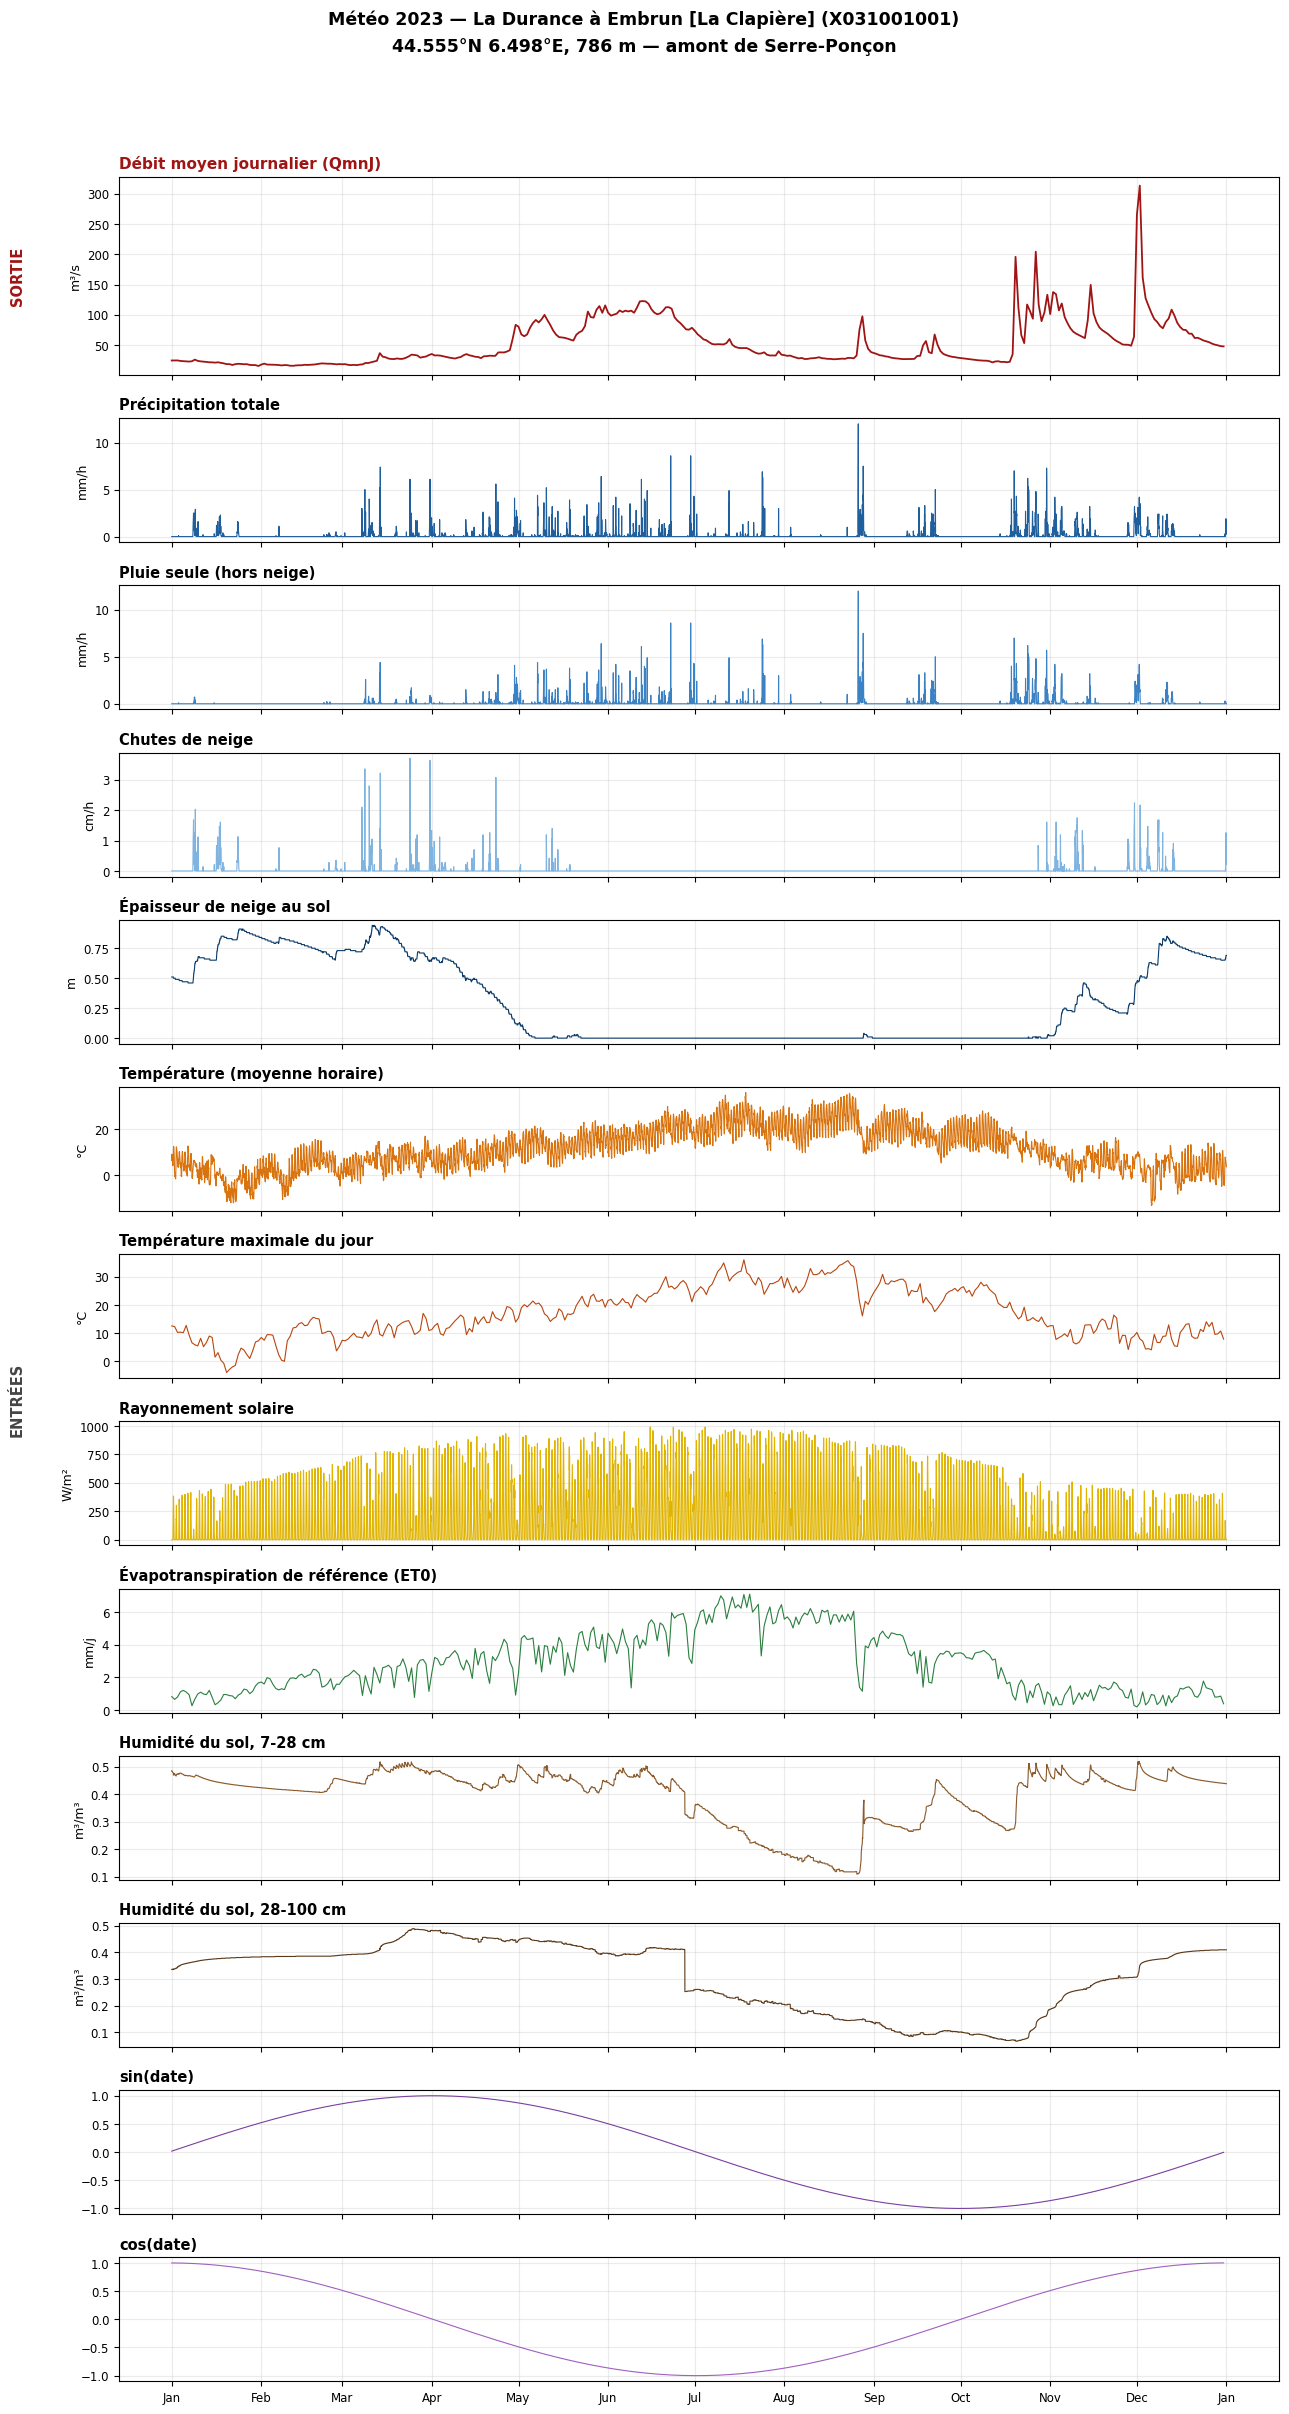

In [7]:
# (colonne, table, titre, unité, couleur)
VARS = [
    ("precipitation", df_h, "Précipitation totale", "mm/h", "#1f5f9e"),
    ("rain", df_h, "Pluie seule (hors neige)", "mm/h", "#3b82c4"),
    ("snowfall", df_h, "Chutes de neige", "cm/h", "#7fb3e0"),
    ("snow_depth", df_h, "Épaisseur de neige au sol", "m", "#0b3b6b"),
    ("temperature_2m", df_h, "Température (moyenne horaire)", "°C", "#d9730d"),
    ("temperature_2m_max", df_j, "Température maximale du jour", "°C", "#b8460e"),
    ("shortwave_radiation", df_h, "Rayonnement solaire", "W/m²", "#e0b400"),
    ("et0_fao_evapotranspiration", df_j, "Évapotranspiration de référence (ET0)", "mm/j", "#2a7f3f"),
    ("soil_moisture_7_to_28cm", df_h, "Humidité du sol, 7-28 cm", "m³/m³", "#8a5a2b"),
    ("soil_moisture_28_to_100cm", df_h, "Humidité du sol, 28-100 cm", "m³/m³", "#5c3a1a"),
    ("sin_date", df_j, "sin(date)", "", "#7a3fa0"),
    ("cos_date", df_j, "cos(date)", "", "#a05fc0"),
]

fig, axes = plt.subplots(len(VARS) + 1, 1, figsize=(13, 24), sharex=True,
                          gridspec_kw={"height_ratios": [1.6] + [1] * len(VARS)})

ax0 = axes[0]
ax0.plot(df_q["date"], df_q["debit_m3_s"], color="#a01414", lw=1.3)
ax0.set_ylabel("m³/s", fontsize=9)
ax0.set_title("Débit moyen journalier (QmnJ)", fontsize=11, loc="left", fontweight="bold", color="#a01414")
ax0.grid(alpha=.25)
ax0.tick_params(labelsize=8.5)

for ax, (col, df, titre, unite, couleur) in zip(axes[1:], VARS):
    ax.plot(df["date"], df[col], color=couleur, lw=0.8)
    ax.set_ylabel(unite, fontsize=9)
    ax.set_title(titre, fontsize=10.5, loc="left", fontweight="bold")
    ax.grid(alpha=.25)
    ax.tick_params(labelsize=8.5)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

titre = (f"Météo {ANNEE} — {STATION_NOM} ({STATION_CODE})\n"
         f"{LAT:.3f}°N {LON:.3f}°E, {ALTITUDE_STATION_M:.0f} m — amont de Serre-Ponçon")
fig.suptitle(titre, fontsize=12.5, fontweight="bold", y=1.004, linespacing=1.7)
fig.tight_layout(rect=[0.04, 0, 1, 0.975])

pos0 = ax0.get_position()
fig.text(0.018, (pos0.y0 + pos0.y1) / 2, "SORTIE", rotation=90, va="center", ha="center",
          fontsize=10.5, fontweight="bold", color="#a01414")
pos1, posN = axes[1].get_position(), axes[-1].get_position()
fig.text(0.018, (pos1.y1 + posN.y0) / 2, "ENTRÉES", rotation=90, va="center", ha="center",
          fontsize=10.5, fontweight="bold", color="#444444")

plt.show()

## 6. Encodage cyclique — représentation circulaire

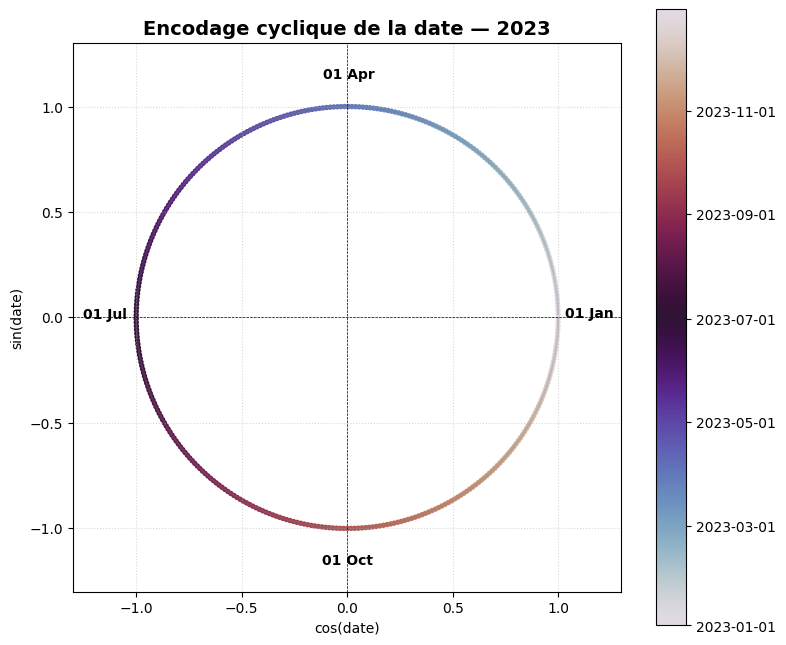

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
x_cos = df_j["cos_date"].to_numpy()
y_sin = df_j["sin_date"].to_numpy()
couleurs = mdates.date2num(df_j["date"])

scatter = ax.scatter(x_cos, y_sin, c=couleurs, cmap="twilight", s=15, edgecolors="none")
ax.plot(x_cos, y_sin, color="gray", alpha=0.3, linestyle="-")

for idx_jour in [0, 90, 181, 273]:
    date_label = df_j["date"].iloc[idx_jour].strftime("%d %b")
    ax.text(x_cos[idx_jour] * 1.15, y_sin[idx_jour] * 1.15, date_label,
            fontsize=10, fontweight="bold", ha="center", va="center")

ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax.axvline(0, color="black", linewidth=0.5, linestyle="--")
ax.set_xlim([-1.3, 1.3])
ax.set_ylim([-1.3, 1.3])
ax.set_aspect("equal")
ax.set_title(f"Encodage cyclique de la date — {ANNEE}", fontweight="bold", fontsize=14)
ax.set_xlabel("cos(date)")
ax.set_ylabel("sin(date)")
ax.grid(True, linestyle=":", alpha=0.5)

cbar = fig.colorbar(scatter, ax=ax, orientation="vertical", shrink=0.8)
cbar.ax.yaxis.set_major_locator(mdates.MonthLocator(interval=2))
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

plt.tight_layout()
plt.show()

## 7. Observations

- Débit : ~25 m³/s (hiver), pic ~120 m³/s (fonte, avr.-juin), pics ponctuels jusqu'à 313 m³/s (pluie, automne).
- Neige au sol : 0,5→0,9 m (hiver), fonte avr.-juin, remontée mi-nov.
- Pluie ≈ précipitation totale sauf hiver (écart = neige).
- Humidité sol surface : 0,45→0,12 m³/m³ (été) ; couche profonde plus lissée et en retard.
- Température/rayonnement : cycle saisonnier standard.

## 8. Corrélation débit ↔ variables

**Coefficient de corrélation de Pearson :**

$$r_{X,Y} = \frac{\mathrm{cov}(X,Y)}{\sigma_X\,\sigma_Y}
= \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2}\sqrt{\sum_i(y_i-\bar y)^2}}$$

**Propriétés :**
- $r \in [-1, 1]$ ; $|r| = 1$ ⇔ relation linéaire exacte, $r = 0$ ⇔ pas de relation LINÉAIRE (n'exclut pas une relation non linéaire).
- Symétrique : $r(X,Y) = r(Y,X)$.
- Invariante par transformation affine de $X$ ou $Y$ (au signe près selon le signe de la pente).
- Sensible aux valeurs aberrantes (non robuste).
- Ne mesure ni la causalité ni un effet décalé dans le temps (un lien retardé, ex. fonte de neige, peut donner un $r$ instantané faible).

In [9]:
# Agrégation journalière des variables horaires (le débit est journalier) :
# somme pour les cumuls, moyenne pour les grandeurs d'état.
agg_sum = ["precipitation", "rain", "snowfall"]
agg_mean = ["snow_depth", "temperature_2m", "shortwave_radiation",
            "soil_moisture_7_to_28cm", "soil_moisture_28_to_100cm"]

par_jour = df_h.set_index("date").resample("1D")
df_h_jour = pd.concat([par_jour[agg_sum].sum(), par_jour[agg_mean].mean()], axis=1).reset_index()

df_corr = (df_q[["date", "debit_m3_s"]]
           .merge(df_h_jour, on="date")
           .merge(df_j[["date", "temperature_2m_max", "et0_fao_evapotranspiration",
                         "sin_date", "cos_date"]], on="date"))
print("valeurs manquantes après fusion :", df_corr.isna().sum().sum())

correlations = df_corr.drop(columns="date").corr()["debit_m3_s"].drop("debit_m3_s")
correlations = correlations.sort_values(key=abs, ascending=False)
correlations.to_frame("r (Pearson)")

valeurs manquantes après fusion : 0


,r (Pearson)
rain,0.448662
precipitation,0.414177
soil_moisture_7_to_28cm,0.323311
snow_depth,-0.306077
sin_date,-0.157596
cos_date,-0.124574
shortwave_radiation,-0.113058
et0_fao_evapotranspiration,-0.084287
soil_moisture_28_to_100cm,0.067491
temperature_2m,0.052893


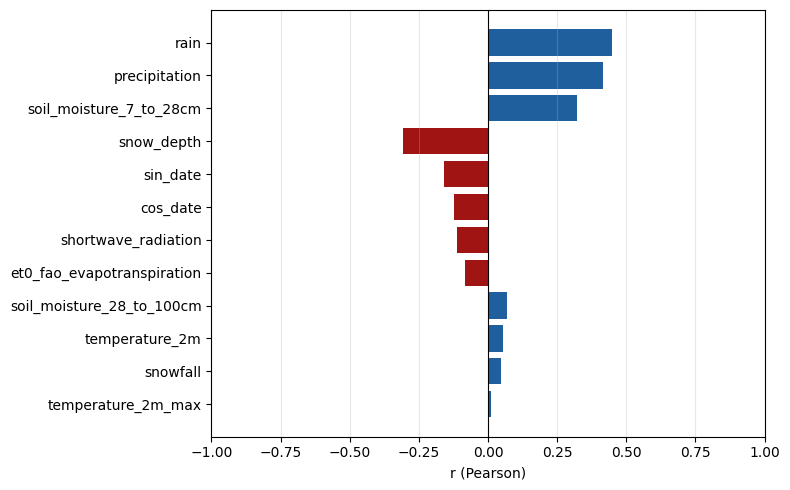

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
couleurs = ["#1f5f9e" if v >= 0 else "#a01414" for v in correlations.values][::-1]
ax.barh(correlations.index[::-1], correlations.values[::-1], color=couleurs)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("r (Pearson)")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()

## 9. Matrice de corrélation

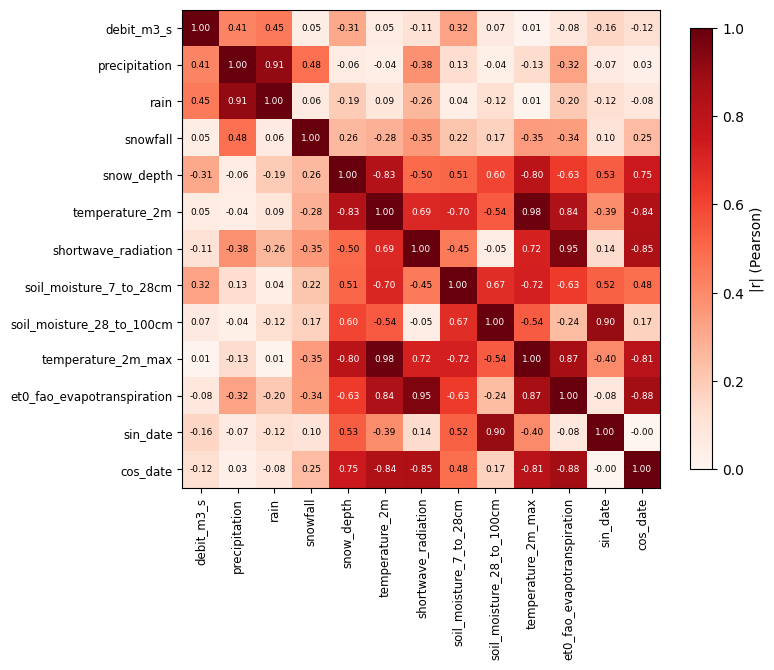

In [11]:
mat = df_corr.drop(columns="date").corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(mat.abs(), cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(mat))); ax.set_xticklabels(mat.columns, rotation=90, fontsize=8.5)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.columns, fontsize=8.5)
for i in range(len(mat)):
    for j in range(len(mat)):
        ax.text(j, i, f"{mat.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(mat.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.85, label="|r| (Pearson)")
plt.tight_layout()
plt.show()

## 10. Corrélation par décalage temporel

$r$ entre débit($t$) et variable($t-\ell$), $\ell = 0$ à $20$ jours — répond à la
limite « pas de délai » du §8 (cf. `river.py::selection_correlation_neige`, même idée).

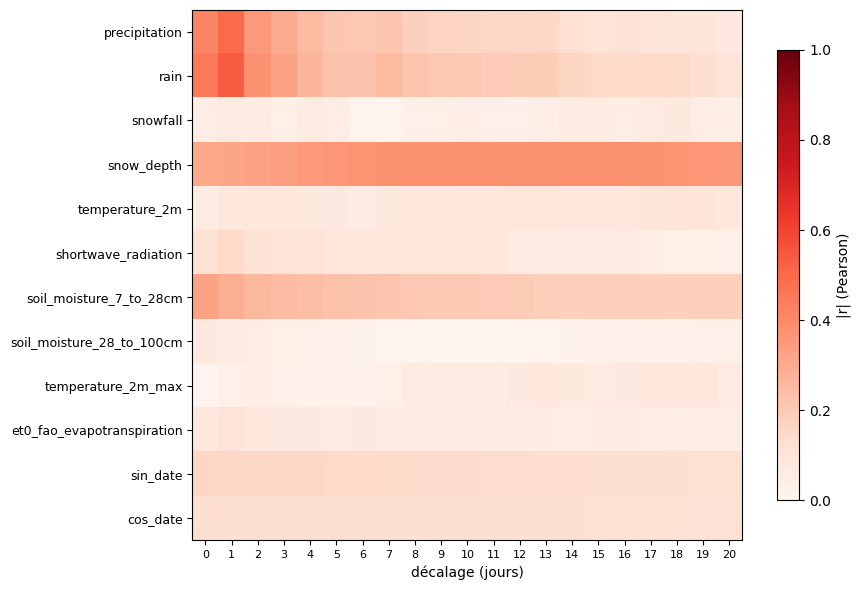

In [12]:
LAGS = range(0, 21)
variables = [c for c in df_corr.columns if c not in ("date", "debit_m3_s")]
serie = df_corr.set_index("date")

def correlation_par_lag(var):
    return pd.Series({l: serie["debit_m3_s"].corr(serie[var].shift(l)) for l in LAGS})

lag_corr = pd.DataFrame({v: correlation_par_lag(v) for v in variables}).T

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(lag_corr.abs(), cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(lag_corr))); ax.set_yticklabels(lag_corr.index, fontsize=9)
ax.set_xticks(range(len(LAGS))); ax.set_xticklabels(LAGS, fontsize=8)
ax.set_xlabel("décalage (jours)")
fig.colorbar(im, ax=ax, shrink=0.85, label="|r| (Pearson)")
plt.tight_layout()
plt.show()

In [13]:
meilleur_lag = pd.DataFrame({
    "lag_optimal_j": lag_corr.abs().idxmax(axis=1),
    "r_lag_optimal": [lag_corr.loc[v, lag_corr.loc[v].abs().idxmax()] for v in lag_corr.index],
    "r_lag_0": lag_corr[0],
}).sort_values("r_lag_optimal", key=abs, ascending=False)
meilleur_lag

,lag_optimal_j,r_lag_optimal,r_lag_0
rain,1,0.537693,0.448662
precipitation,1,0.496534,0.414177
snow_depth,13,-0.382426,-0.306077
soil_moisture_7_to_28cm,0,0.323311,0.323311
sin_date,0,-0.157596,-0.157596
shortwave_radiation,1,-0.145340,-0.113058
cos_date,4,-0.125199,-0.124574
et0_fao_evapotranspiration,1,-0.099999,-0.084287
temperature_2m,18,0.098888,0.052893
temperature_2m_max,18,0.085650,0.011089


## 11. ACP (PCA / POD) des variables d'entrée

Combinaisons linéaires orthogonales des entrées standardisées (mêmes maths que la POD).
Deux quantités distinctes : la **variance expliquée** (part de la variabilité des
entrées captée par chaque axe, propriété du PCA seul) et la **corrélation au débit**
(si cet axe est lié à la sortie, quelle que soit sa part de variance). Le signe d'une
composante est arbitraire : seule $|r|$ a un sens.

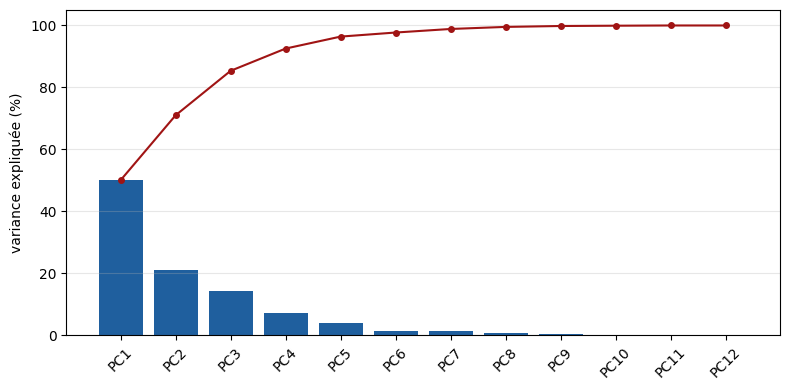

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

variables = [c for c in df_corr.columns if c not in ("date", "debit_m3_s")]
X = StandardScaler().fit_transform(df_corr[variables])
pca = PCA().fit(X)
scores = pca.transform(X)

df_pc = pd.DataFrame(scores, columns=[f"PC{k+1}" for k in range(len(variables))])
df_pc["date"] = df_corr["date"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df_pc.columns[:-1], pca.explained_variance_ratio_ * 100, color="#1f5f9e")
ax.plot(df_pc.columns[:-1], np.cumsum(pca.explained_variance_ratio_) * 100,
        color="#a01414", marker="o", ms=4)
ax.set_ylabel("variance expliquée (%)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

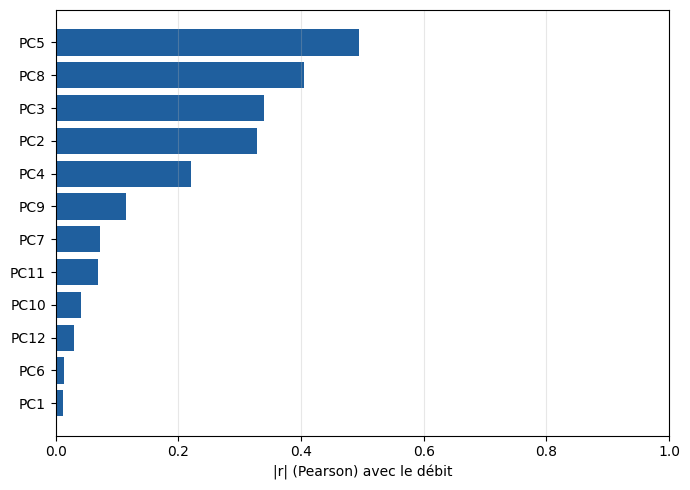

In [15]:
corr_debit_pc = (df_pc.merge(df_corr[["date", "debit_m3_s"]], on="date")
                  .drop(columns="date").corr()["debit_m3_s"].drop("debit_m3_s")
                  .abs().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr_debit_pc.index[::-1], corr_debit_pc.values[::-1], color="#1f5f9e")
ax.set_xlim(0, 1)
ax.set_xlabel("|r| (Pearson) avec le débit")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()

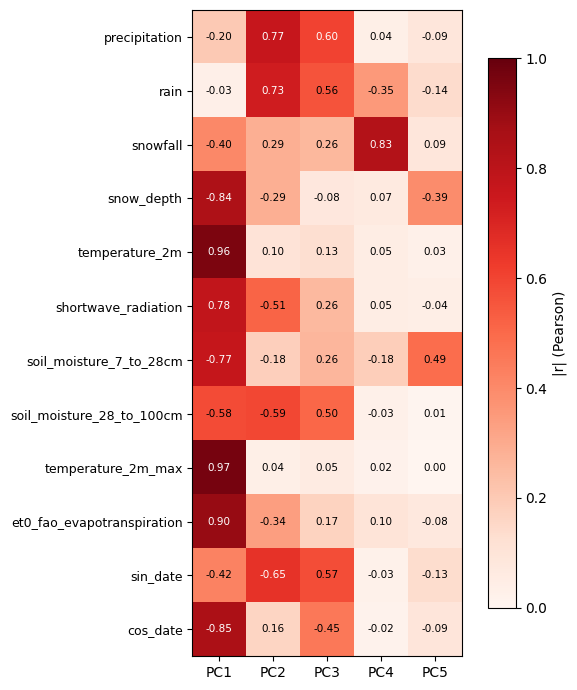

In [16]:
n_aff = 5   # 96 % de la variance des entrées (cf. graphique précédent)
struct = (df_pc.merge(df_corr[["date"] + variables], on="date")
          .drop(columns="date").corr().loc[variables, df_pc.columns[:n_aff]])

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(struct.abs(), cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(n_aff)); ax.set_xticklabels(struct.columns)
ax.set_yticks(range(len(variables))); ax.set_yticklabels(variables, fontsize=9)
for i in range(len(variables)):
    for j in range(n_aff):
        ax.text(j, i, f"{struct.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(struct.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.85, label="|r| (Pearson)")
plt.tight_layout()
plt.show()